# Análisis y optimización de un portafolio de acciones

Este notebook construye, paso a paso, un portafolio con **cualquier cantidad de acciones**.
Cada sección explica *qué* se calcula y *por qué* importa, y luego lo muestra con tablas y gráficas.

**Ruta:** datos → rendimientos → métricas por activo → correlación → estimación → estrategias →
frontera eficiente → validación fuera de muestra → portafolio final → tu portafolio actual → simulación de escenarios futuros → laboratorio interactivo.

> Esto es un ejercicio cuantitativo y educativo, no una recomendación de inversión.

In [1]:
# Librerías (todas viven en libs.py) y la lógica del análisis (acciones.py)
from libs import pd, np, plt, widgets, display, Markdown, replace
import acciones as ac

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

Librerias descargadas correctamente


## 1. Elige tus acciones

Escribe en el panel las acciones que quieras analizar (símbolos de [Yahoo Finance](https://finance.yahoo.com),
p. ej. `AAPL`, `KO`, `WALMEX.MX`) y pulsa **Analizar**: todas las secciones de abajo se recalculan.

- **Desde:** inicio del periodo histórico. Más años = estimaciones más estables, pero quizá menos actuales.
- **Benchmark:** índice para comparar (SPY = S&P 500). Déjalo vacío para no usar ninguno.
- **Capital:** dinero a invertir desde cero, para calcular cuántas acciones comprar.
- **Mis acciones** (opcional): cuántas acciones tienes hoy de cada empresa, p. ej. `AAPL: 10, KO: 25`. Se analiza
  tu portafolio actual y se calcula qué comprar o vender para mejorarlo (sección 11).

Los parámetros avanzados (peso máximo, estimadores, regularización, periodo de prueba) se exploran en los
**laboratorios** del final.

> En Jupyter, los valores iniciales están en la celda de abajo. Tras usar el panel, ejecuta las celdas
> siguientes (*Run Selected Cell and All Below*) para actualizar las secciones.

In [2]:
cfg_inicial = ac.Config(
    tickers=["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "JPM", "KO", "XOM"],
    inicio="2021-01-01",      # fin: por defecto, hoy
    benchmark="SPY",
    capital=10_000,
    posiciones="AAPL: 10, NVDA: 40, KO: 15, XOM: 5",   # ejemplo: tus acciones actuales (o None)
    # Avanzados (valores por defecto): max_peso=0.40, mu="historico", cov="ledoit-wolf",
    # gamma=0.1, test=0.30, rebalanceo="mensual", horizonte=5, prima_mercado=0.05
)

tab = ac.Tablero()          # detecta si corre como app (Voilà) o como notebook
tab.analizar(cfg_inicial)
display(tab.panel())

Descargando 8 activos (2021-01-01 → 2026-11-11)...


  Activos válidos: AAPL, AMZN, GOOGL, JPM, KO, MSFT, NVDA, XOM
  Periodo efectivo: 2021-01-04 → 2026-11-10 (1471 días)


## 2. Datos: precios ajustados

Se usan **precios ajustados**: incorporan dividendos y *splits*, así que reflejan el rendimiento total real
(si una acción hace un split 2:1, el precio sin ajustar "cae" 50 % sin que nadie pierda dinero).

La limpieza descarta tickers inválidos o con historial demasiado corto (una acción que salió a bolsa hace poco
recortaría todo el periodo), rellena huecos cortos y alinea las fechas.

La **tasa libre de riesgo** es lo que ganarías sin riesgo (bonos del Tesoro a 3 meses, `^IRX`). Es la vara
para medir si el riesgo de las acciones "valió la pena".

**Cómo leer la gráfica:** todas parten de 100. Si una línea termina en 250, 100 invertidos se convirtieron
en 250. La línea punteada es el benchmark: lo que habrías obtenido comprando el índice completo.

**Tasa libre de riesgo promedio del periodo:** 3.29%

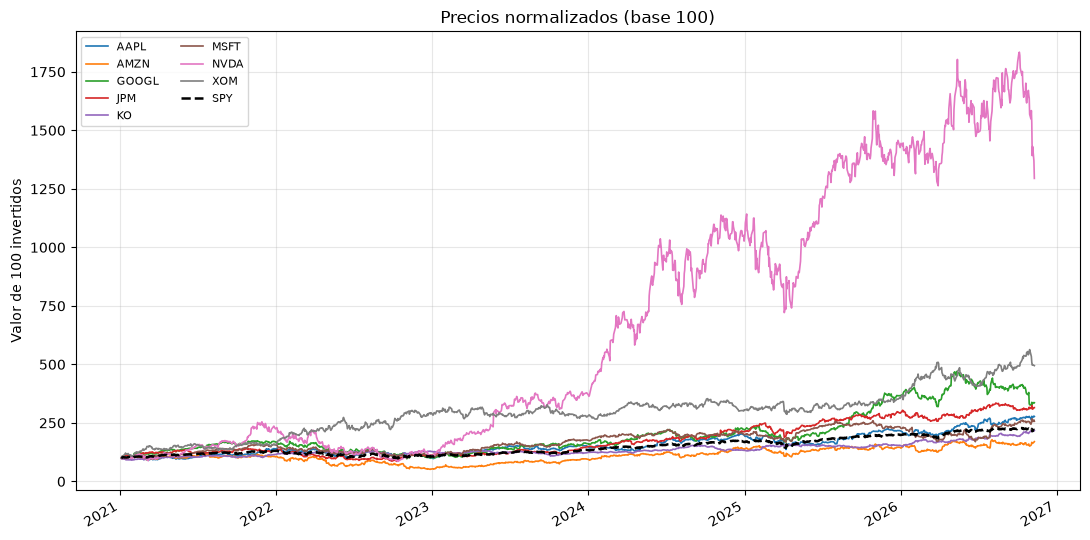

> **Tus resultados**
>
> - Periodo analizado: **2021-01-04 → 2026-11-10** (≈ 5.8 años, 8 acciones).
> - Mejor: **NVDA** (+1195%). Peor: **AMZN** (+70%).
> - **6 de 8** acciones superaron a SPY (+120%).

In [3]:
@tab.seccion
def _():
    A = tab.A
    display(Markdown(f"**Tasa libre de riesgo promedio del periodo:** {A.rf:.2%}"))
    ac.graf_precios(A.precios, A.bench); plt.show()
    display(Markdown(ac.lectura_precios(A.precios, A.bench)))

## 3. Rendimientos diarios

Los precios no son comparables entre sí (una acción de \$500 no es "mejor" que una de \$50); los **rendimientos** sí:

$$r_t = \frac{P_t}{P_{t-1}} - 1$$

Para anualizar se usa que hay ~252 días hábiles al año: la media se multiplica por 252 y la volatilidad por
$\sqrt{252}$ (la varianza crece con el tiempo; la desviación estándar, con su raíz).

**Cómo leer la gráfica:** la mayoría de los días se mueven cerca de 0 %, pero hay colas (días muy malos o muy
buenos). La línea roja es el **VaR 95 %**: en 1 de cada 20 días la pérdida fue *peor* que ese valor.
Colas más largas de lo que predice una campana normal = **curtosis** alta = sorpresas más frecuentes.

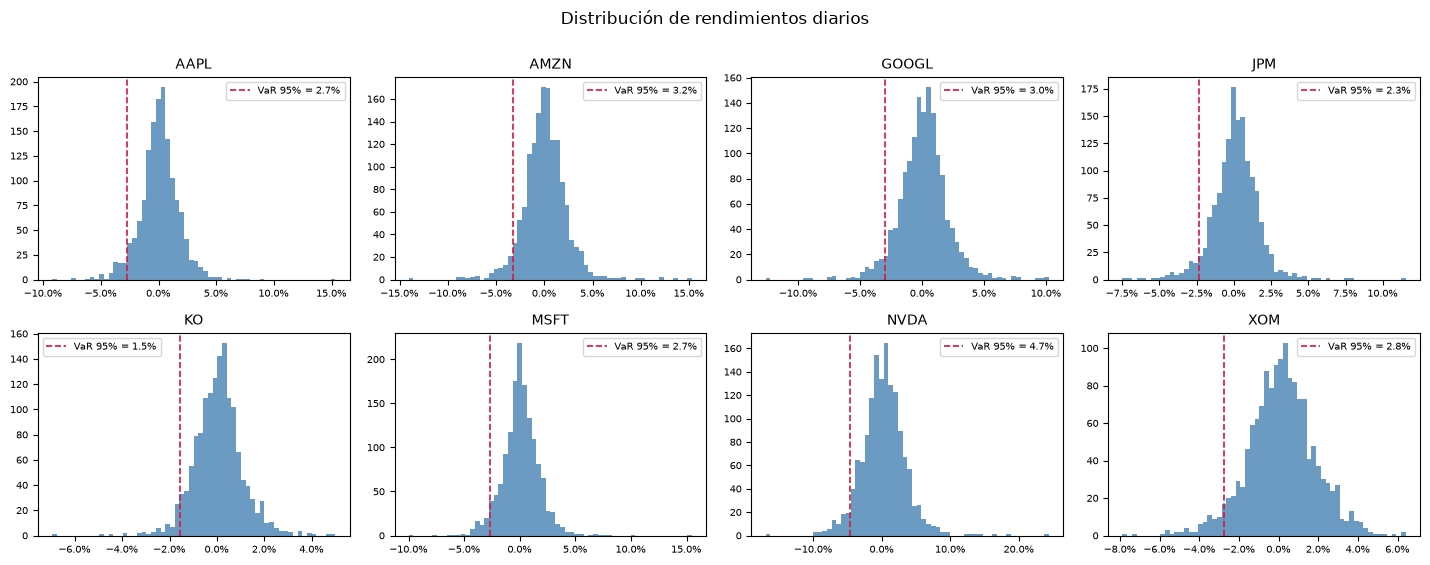

In [4]:
@tab.seccion
def _():
    ac.graf_distribucion(tab.A.rend)

## 4. Métricas por activo

| Métrica | Qué mide | Mejor si... |
|---|---|---|
| **CAGR** | Rendimiento anual compuesto realmente obtenido | Alto |
| **Volatilidad** | Desviación estándar anualizada: cuánto "se mueve" | Bajo |
| **Sharpe** | $\frac{R - R_f}{\sigma}$: rendimiento extra por unidad de riesgo | Alto (>1 es muy bueno) |
| **Sortino** | Como Sharpe, pero solo penaliza la volatilidad *a la baja* | Alto |
| **Máx. drawdown** | Peor caída desde un máximo hasta un mínimo | Cercano a 0 |
| **Calmar** | CAGR / \|máx. drawdown\| | Alto |
| **VaR / CVaR 95 %** | Pérdida diaria en el peor 5 % de días / promedio de ese peor 5 % | Bajo |
| **Asimetría** | Negativa = caídas grandes más frecuentes que subidas grandes | ≥ 0 |
| **Curtosis** | Colas gruesas (eventos extremos) | Bajo |
| **Beta** | Sensibilidad al mercado: beta 1.5 → si el mercado cae 10 %, tiende a caer 15 % | Depende |
| **Alfa** | Rendimiento que *no* explica el mercado (según CAPM) | Alto |
| **Information ratio** | Rendimiento extra vs. benchmark / variabilidad de esa diferencia | Alto |

**Cómo leer la gráfica:** arriba a la izquierda es el lugar ideal (mucho rendimiento, poco riesgo).
Dos acciones con el mismo rendimiento no son iguales si una lo logra con el doble de volatilidad.

,Rend. total,Rend. anual (CAGR),Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% diario,CVaR 95% diario,Asimetría,Curtosis,% días positivos,Beta,Alfa anual,Tracking error,Information ratio
AAPL,177.40%,19.11%,27.63%,0.65,0.96,-33.36%,0.57,2.70%,3.89%,0.35,6.10,52.93%,1.17,4.44%,19.75%,0.33
AMZN,70.00%,9.52%,35.14%,0.34,0.50,-56.15%,0.17,3.23%,4.84%,0.35,5.82,51.22%,1.45,-4.91%,26.53%,0.01
GOOGL,236.14%,23.10%,31.58%,0.71,1.04,-44.32%,0.52,2.99%,4.40%,-0.00,4.03,53.20%,1.25,7.98%,24.06%,0.45
JPM,215.39%,21.76%,24.04%,0.80,1.17,-38.77%,0.56,2.34%,3.48%,0.09,4.67,54.01%,0.87,9.19%,19.25%,0.40
KO,117.64%,14.26%,16.45%,0.70,1.02,-17.27%,0.83,1.55%,2.20%,-0.06,3.24,52.93%,0.26,8.44%,20.13%,-0.01
MSFT,156.86%,17.55%,27.41%,0.61,0.91,-37.15%,0.47,2.67%,3.67%,0.55,7.01,51.90%,1.13,3.48%,19.96%,0.25
NVDA,1194.55%,55.11%,50.56%,1.06,1.62,-66.34%,0.83,4.66%,6.56%,0.49,4.51,53.06%,2.10,28.95%,40.83%,1.02
XOM,394.63%,31.53%,27.21%,1.03,1.50,-20.51%,1.54,2.75%,3.78%,-0.18,1.07,53.81%,0.42,23.05%,28.05%,0.58
[SPY],119.54%,14.43%,16.69%,0.70,1.00,-24.50%,0.59,1.62%,2.42%,0.23,8.89,54.22%,1.00,-0.00%,0.00%,-


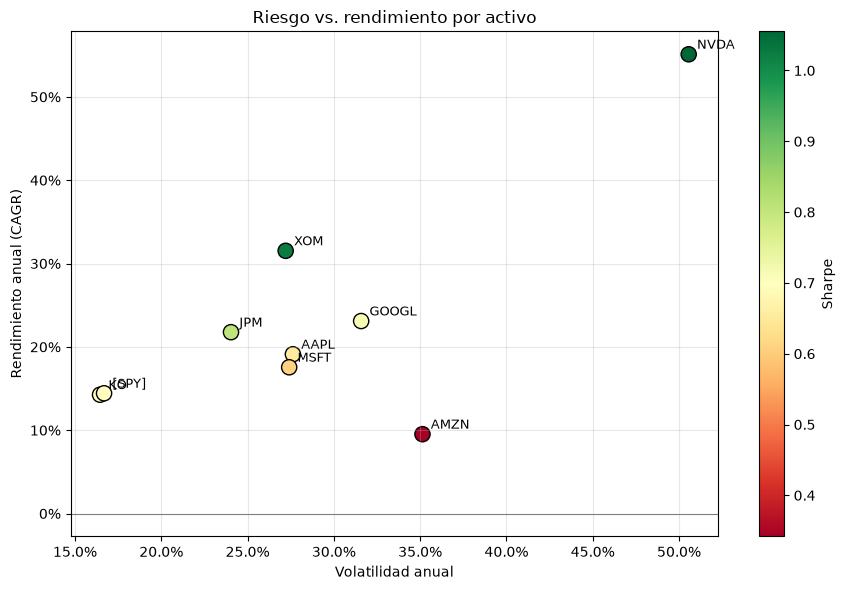

> **Tus resultados**
>
> - Mejor rendimiento por riesgo (Sharpe): **NVDA** (1.06); peor: **AMZN** (0.34).
> - Más volátil: **NVDA** (51% anual); más estable: **KO** (16%).
> - Peor caída: **NVDA** llegó a perder 66% desde su máximo.
> - Más sensible al mercado: **NVDA** (beta 2.10); más defensiva: **KO** (beta 0.26).

In [5]:
@tab.seccion
def _():
    A = tab.A
    display(ac.estilo(A.met_activos))
    ac.graf_riesgo_rendimiento(A.met_activos); plt.show()
    display(Markdown(ac.lectura_metricas(A.met_activos, A.rf)))

## 5. Correlación: la clave de la diversificación

La volatilidad de un portafolio **no** es el promedio de las volatilidades:

$$\sigma_p^2 = \sum_i \sum_j w_i w_j \sigma_i \sigma_j \rho_{ij}$$

Si dos activos tienen correlación $\rho$ baja, cuando uno cae el otro no necesariamente lo hace, y el portafolio
oscila menos que cada uno por separado. Es "el único almuerzo gratis" de las finanzas.

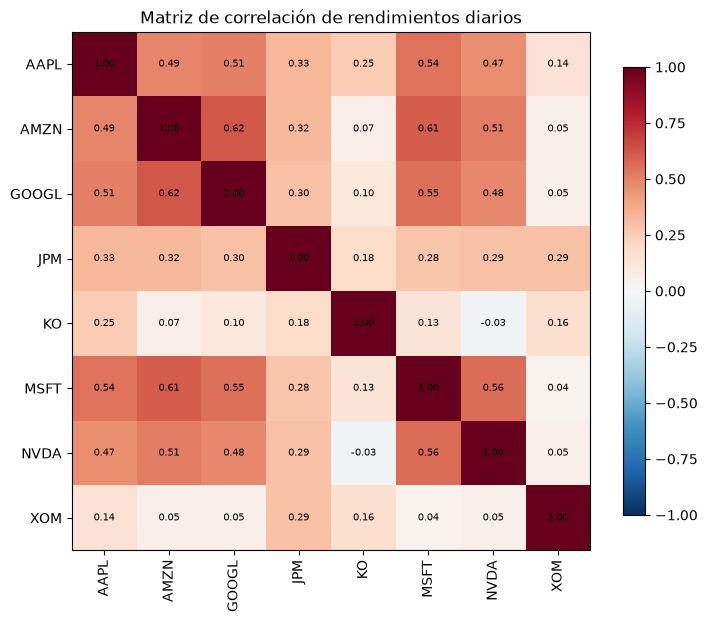

> **Tus resultados**
>
> - Correlación promedio **0.30**, baja: buena diversificación.
> - Par más parecido: **AMZN / GOOGL** (0.62). Par más complementario: **KO / NVDA** (-0.03).

In [6]:
@tab.seccion
def _():
    A = tab.A
    ac.graf_correlacion(A.corr); plt.show()
    if len(A.corr) > 1:
        altos, bajos = ac.pares_correlacion(A.corr)
        display(pd.concat({"Más correlacionados (diversifican poco)": altos.reset_index(),
                           "Menos correlacionados (diversifican más)": bajos.reset_index()}, axis=1)
                  .style.format(precision=2).hide(axis="index"))
    display(Markdown(ac.lectura_correlacion(A.corr)))

## 6. Estimar el futuro: rendimiento esperado (μ) y covarianza (Σ)

Optimizar requiere dos insumos: cuánto esperamos que rinda cada acción (**μ**) y cómo se mueven juntas (**Σ**).
Ambos se estiman con el pasado, y **ahí está el punto débil de toda la teoría**:

- **μ es muy ruidoso.** Con pocos años de datos, el error al estimar el rendimiento anual de una acción puede ser
  de ±10–15 puntos. El optimizador "se enamora" de quien tuvo suerte en el pasado.
- **Σ es más estable**, pero con muchos activos la matriz muestral es poco fiable. **Ledoit-Wolf** la "encoge"
  hacia una estructura más simple, lo que reduce errores extremos.

Por eso el análisis usa límites de peso, regularización y, sobre todo, **validación fuera de muestra** (sección 9).

In [7]:
@tab.seccion
def _():
    A = tab.A
    display(pd.DataFrame({
        "μ esperado": A.mu,
        "Volatilidad (Ledoit-Wolf)": np.sqrt(np.diag(A.S)),
        "Volatilidad (muestral)": np.sqrt(np.diag(A.S_muestral)),
    }).style.format("{:.2%}"))
    display(Markdown(f"**Número de condición de Σ** (más bajo = más estable al invertirla): "
                     f"muestral {np.linalg.cond(A.S_muestral):,.0f} · Ledoit-Wolf {np.linalg.cond(A.S):,.0f}"))

,μ esperado,Volatilidad (Ledoit-Wolf),Volatilidad (muestral)
Ticker,,,
AAPL,19.11%,27.66%,27.63%
AMZN,9.52%,35.09%,35.14%
GOOGL,23.10%,31.57%,31.58%
JPM,21.76%,24.13%,24.04%
KO,14.26%,16.69%,16.45%
MSFT,17.55%,27.45%,27.41%
NVDA,55.11%,50.38%,50.56%
XOM,31.53%,27.25%,27.21%


**Número de condición de Σ** (más bajo = más estable al invertirla): muestral 19 · Ledoit-Wolf 18

## 7. Siete estrategias para construir el portafolio

| Estrategia | Idea | Usa μ | Usa Σ |
|---|---|:-:|:-:|
| **Igual peso** | $1/N$ a cada acción. Simple y sorprendentemente difícil de superar | No | No |
| **Inversa volatilidad** | Más peso a las acciones menos volátiles | No | Solo diagonal |
| **Paridad de riesgo** | Cada acción aporta **el mismo riesgo** (no el mismo dinero) | No | Sí |
| **Mínima volatilidad** | El portafolio menos volátil posible | No | Sí |
| **Máximo Sharpe** | El de mejor rendimiento por unidad de riesgo (Markowitz clásico) | Sí | Sí |
| **Mínimo CVaR** | Minimiza la pérdida promedio en los peores días | Sí | (escenarios) |
| **HRP** | Agrupa acciones parecidas en un árbol y reparte riesgo entre grupos (López de Prado) | No | Sí |

Las que **no usan μ** son más robustas porque evitan el insumo más ruidoso.

**Activos efectivos** $= 1/\sum w_i^2$: con $N$ acciones a igual peso vale $N$; si casi todo está en una sola,
se acerca a 1. Mide qué tan diversificado está *realmente* el portafolio.

,Mi portafolio,Igual peso,Inversa volatilidad,Paridad de riesgo,Mínima volatilidad,Máximo Sharpe,Mínimo CVaR,HRP
Ticker,,,,,,,,
AAPL,27.8%,12.5%,12.4%,9.9%,10.3%,2.8%,-,11.7%
AMZN,-,12.5%,9.8%,8.2%,6.2%,-,-,4.7%
GOOGL,-,12.5%,10.9%,9.2%,9.1%,7.7%,-,5.9%
JPM,-,12.5%,14.3%,13.4%,16.0%,13.2%,18.3%,15.3%
KO,11.6%,12.5%,20.6%,26.3%,26.7%,16.2%,40.0%,37.3%
MSFT,-,12.5%,12.5%,10.4%,12.1%,0.6%,21.7%,8.5%
NVDA,54.0%,12.5%,6.8%,6.2%,1.3%,27.8%,-,2.5%
XOM,6.6%,12.5%,12.6%,16.3%,18.4%,31.7%,19.9%,14.0%


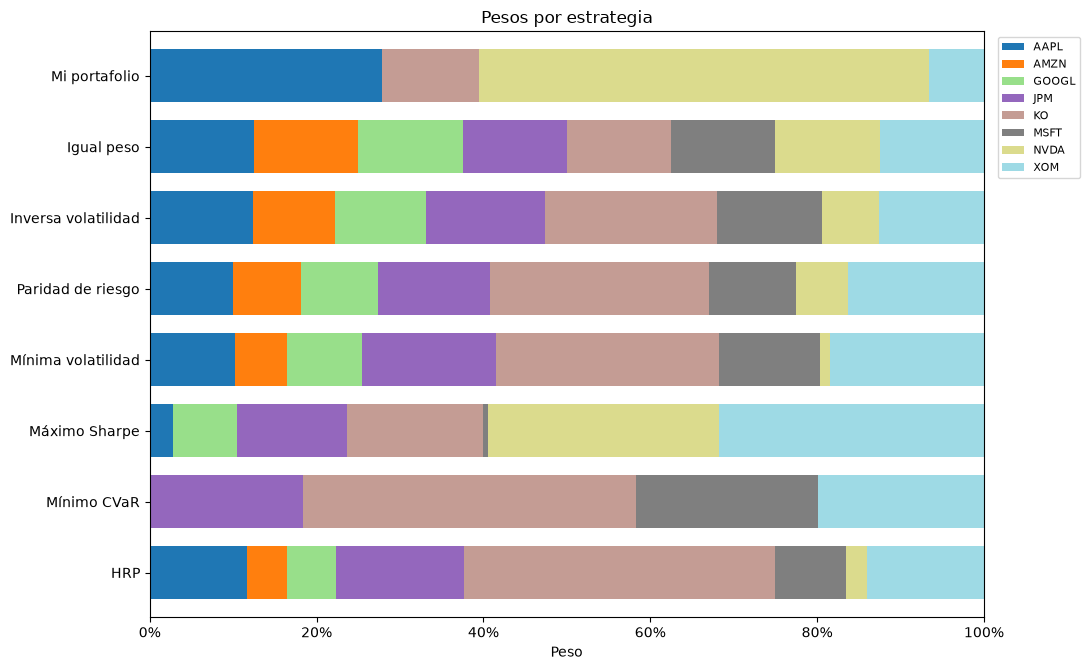

,Rend. esperado,Volatilidad esperada,Sharpe,N° activos,Activos efectivos
Mi portafolio,38.80%,31.83%,1.12,4.00,2.59
Igual peso,23.99%,19.50%,1.06,8.00,8.00
Inversa volatilidad,21.82%,17.02%,1.09,8.00,7.35
Paridad de riesgo,21.89%,15.78%,1.18,8.00,6.51
Mínima volatilidad,20.57%,14.94%,1.16,8.00,5.94
Máximo Sharpe,32.90%,20.44%,1.45,7.00,4.39
Mínimo CVaR,19.79%,13.83%,1.19,4.00,3.56
HRP,20.00%,14.29%,1.17,8.00,4.77


> **Tus resultados**
>
> - Estrategia más concentrada: **Mínimo CVaR** (equivale a 3.6 acciones a igual peso, de 8).
> - Mayor peso individual: **KO** con 40% en *Mínimo CVaR*.
> - Mejor Sharpe *esperado*: **Máximo Sharpe** (1.45), aún sin validar.

In [8]:
@tab.seccion
def _():
    A = tab.A
    display(ac.estilo_pesos(pd.DataFrame(A.pesos)))
    ac.graf_pesos(A.pesos); plt.show()
    display(ac.estilo(A.ex_ante, colorear=("Sharpe", "Activos efectivos")))
    display(Markdown(ac.lectura_pesos(A.pesos, A.ex_ante)))

## 8. Frontera eficiente

Cada punto de color es un portafolio aleatorio. La **línea negra** es la frontera eficiente: para cada nivel de
riesgo, el máximo rendimiento esperado posible. Ningún portafolio puede estar por encima de ella (según las estimaciones).

**Ojo:** esta gráfica usa las estimaciones de todo el historial, así que "Máximo Sharpe" siempre se ve espectacular
*aquí*. La pregunta real es si eso se mantiene en datos que el modelo no vio.

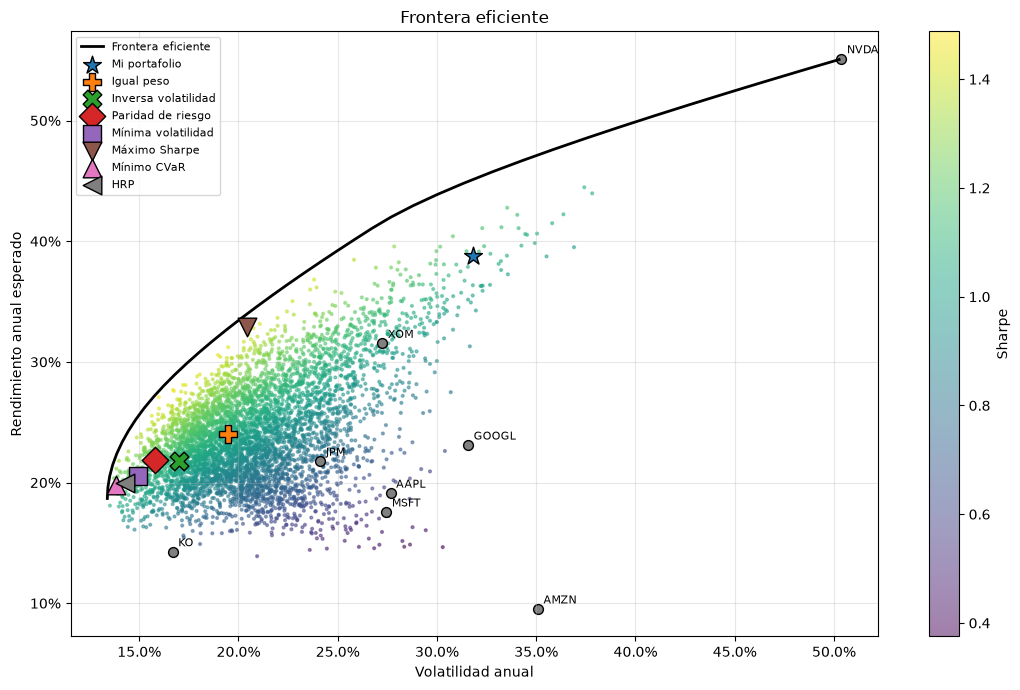

In [9]:
@tab.seccion
def _():
    A = tab.A
    ac.graf_frontera(A.mu, A.S, A.pesos, A.rf)

## 9. Validación fuera de muestra (la prueba de fuego)

1. Se toma la primera parte del periodo (*entrenamiento*) y con ella se calculan los pesos de cada estrategia.
2. Se "congela" ese portafolio y se mide qué pasó en la parte final (*prueba*), rebalanceando periódicamente.

Así se simula lo que habría vivido un inversionista real: decidir con la información disponible y luego esperar.
Si una estrategia brilla dentro de muestra pero no fuera, estaba **sobreajustada** (*overfitting*).

**Cómo leer las gráficas:** la primera muestra cuánto habrías ganado; la segunda, cuánto habrías sufrido en el
camino. La última compara el Sharpe dentro y fuera de muestra: las optimizaciones siempre lucen mejor con los datos
con los que fueron entrenadas.

**Entrenamiento (70%):** 2021-01-04 → 2025-02-06 · **Prueba (30%):** 2025-02-07 → 2026-11-10

,Rend. total,Rend. anual (CAGR),Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% diario,CVaR 95% diario,Asimetría,Curtosis,% días positivos,Beta,Alfa anual,Tracking error,Information ratio
HRP,53.85%,27.84%,12.56%,1.76,2.78,-11.97%,2.33,0.94%,1.53%,0.43,13.08,55.66%,0.47,16.77%,13.35%,0.80
Mínimo CVaR,52.88%,27.38%,12.74%,1.71,2.67,-9.45%,2.90,1.07%,1.57%,0.08,8.97,56.79%,0.36,17.60%,15.61%,0.66
Mínima volatilidad,52.30%,27.11%,13.37%,1.62,2.51,-14.18%,1.91,1.12%,1.75%,0.54,16.11,54.52%,0.57,15.10%,11.68%,0.87
Paridad de riesgo,51.53%,26.74%,13.86%,1.55,2.38,-15.43%,1.73,1.16%,1.87%,0.78,19.32,54.52%,0.66,13.88%,9.88%,1.01
Inversa volatilidad,49.66%,25.84%,14.97%,1.39,2.15,-16.86%,1.53,1.29%,2.03%,0.96,18.77,54.98%,0.74,12.34%,8.82%,1.06
Igual peso,47.34%,24.73%,17.23%,1.18,1.79,-19.26%,1.28,1.46%,2.39%,1.00,18.44,55.88%,0.89,10.07%,7.71%,1.15
Máximo Sharpe,49.08%,25.57%,21.66%,1.01,1.48,-20.18%,1.27,1.87%,3.03%,0.38,12.34,55.20%,0.94,11.09%,14.31%,0.73
Mi portafolio,47.77%,24.94%,26.66%,0.85,1.26,-26.23%,0.95,2.25%,3.69%,0.98,14.56,55.43%,1.25,8.22%,16.15%,0.68
[SPY],26.11%,14.14%,17.35%,0.66,0.97,-18.76%,0.75,1.57%,2.45%,1.10,21.94,54.07%,1.00,0.00%,0.00%,-


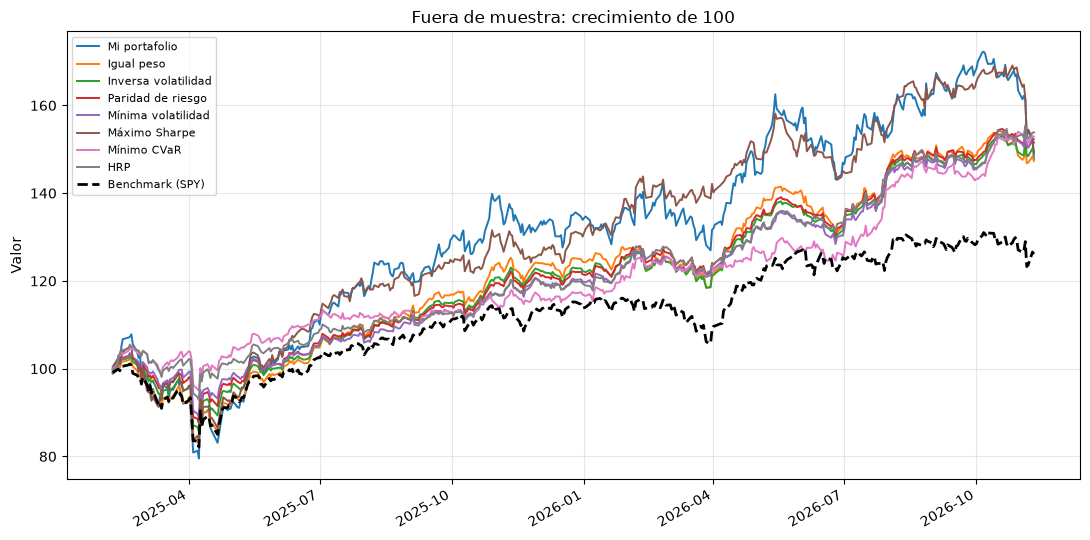

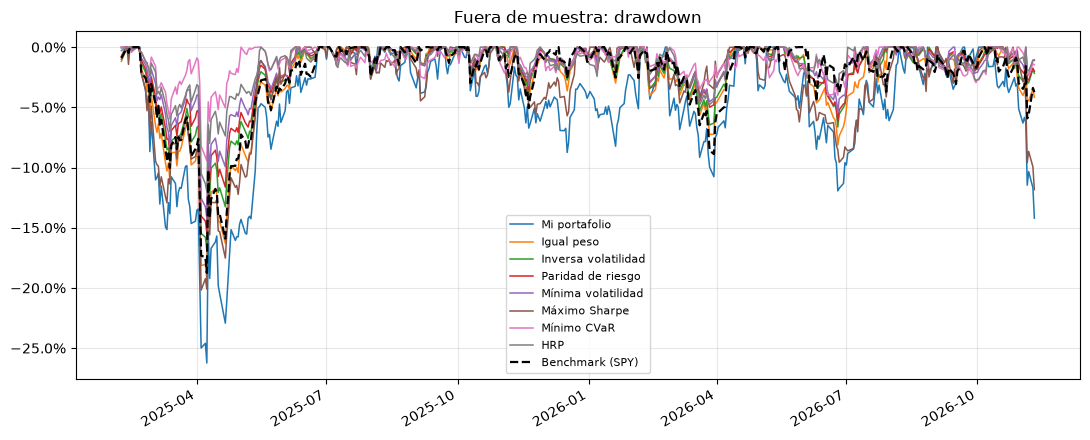

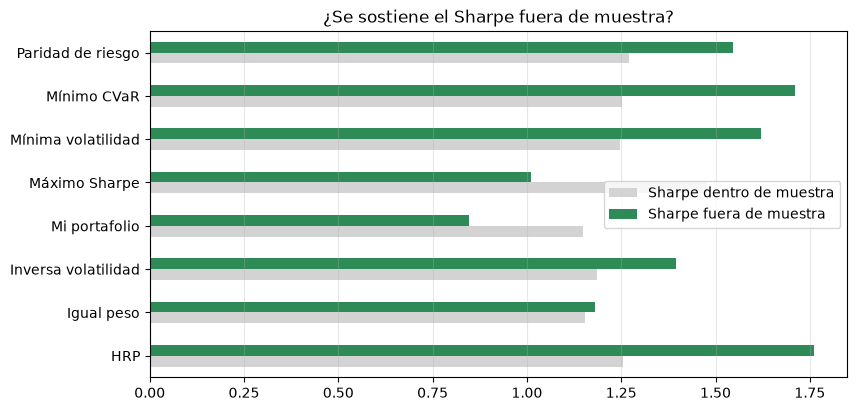

> **Tus resultados**
>
> - Ganadora fuera de muestra: **HRP** (Sharpe 1.76, CAGR 27.8%, peor caída -12.0%).
> - **7 de 7** estrategias superaron el Sharpe del benchmark (0.66).
> - *Máximo Sharpe* quedó #1 dentro de muestra y **#7** fuera de muestra: señal de sobreajuste.

In [10]:
@tab.seccion
def _():
    A, o = tab.A, tab.A.oos
    if o is None:
        display(Markdown("*No hay datos suficientes para validar fuera de muestra "
                         "(se necesita al menos 1 año de entrenamiento). Prueba con una fecha de inicio anterior.*"))
        return
    display(Markdown(f"**Entrenamiento ({1 - A.cfg.test:.0%}):** {o.periodo_train[0]} → {o.periodo_train[1]} · "
                     f"**Prueba ({A.cfg.test:.0%}):** {o.periodo_test[0]} → {o.periodo_test[1]}"))
    display(ac.estilo(o.metricas))
    ac.graf_crecimiento(o.rendimientos, o.benchmark, "Fuera de muestra: crecimiento de 100"); plt.show()
    ac.graf_drawdown(o.rendimientos, o.benchmark, "Fuera de muestra: drawdown"); plt.show()
    sharpe = pd.DataFrame({"Sharpe dentro de muestra": A.met_hist["Sharpe"],
                           "Sharpe fuera de muestra": o.metricas["Sharpe"]}).dropna()
    ax = sharpe.plot.barh(figsize=(9, 4.5), color=["lightgray", "seagreen"])
    ax.set_title("¿Se sostiene el Sharpe fuera de muestra?"); ax.grid(alpha=0.3, axis="x"); plt.show()
    display(Markdown(ac.lectura_oos(o, A.met_hist)))

## 10. Portafolio final

Se sugiere la estrategia que mejor se comportó en la validación (o, si no se pudo validar, la de mejor Sharpe
esperado), y sus pesos se recalculan con **todo** el historial: la información más completa disponible hoy.

La gráfica compara el **dinero** invertido en cada acción con el **riesgo** que aporta. Una acción con 10 % del
capital puede aportar 25 % del riesgo si es muy volátil o está muy correlacionada con las demás.

### Portafolio sugerido: **HRP**  
*Criterio: mejor Sharpe fuera de muestra*

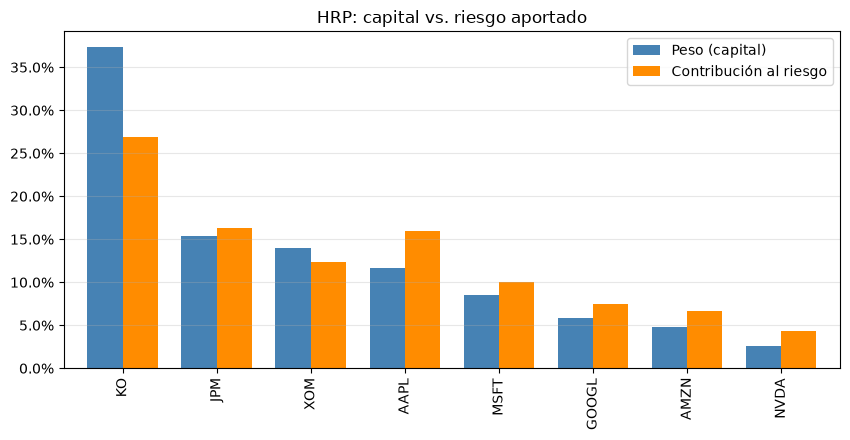

> **Tus resultados**
>
> - Mayor inversión: **KO** (37% del capital).
> - Mayor fuente de riesgo: **KO** (27% del riesgo con 37% del capital).

**Compra con $10,000** (precios del 2026-11-10). Efectivo sobrante: **$67.25**

,Acciones,Precio,Monto,Peso real,Peso objetivo
KO,38,$96.91,"$3,682.58",36.8%,37.3%
JPM,4,$342.07,"$1,368.28",13.7%,15.3%
XOM,8,$164.47,"$1,315.76",13.2%,14.0%
MSFT,2,$533.16,"$1,066.32",10.7%,8.5%
AAPL,3,$348.51,"$1,045.53",10.5%,11.7%
GOOGL,2,$287.38,$574.76,5.7%,5.9%
AMZN,2,$270.87,$541.74,5.4%,4.7%
NVDA,2,$168.89,$337.78,3.4%,2.5%


In [11]:
@tab.seccion
def _():
    A = tab.A
    display(Markdown(f"### Portafolio sugerido: **{A.elegido}**  \n*Criterio: {A.motivo}*"))
    ac.graf_contribucion(A.w, A.S, f"{A.elegido}: capital vs. riesgo aportado"); plt.show()
    display(Markdown(ac.lectura_final(A.elegido, A.w, A.S)))
    if A.cfg.capital:
        compra, sobrante = ac.asignacion_discreta(A.w, A.precios, A.cfg.capital)
        display(Markdown(f"**Compra con ${A.cfg.capital:,.0f}** (precios del {A.precios.index[-1].date()}). "
                         f"Efectivo sobrante: **${sobrante:,.2f}**"))
        display(compra.style.format({"Precio": "${:,.2f}", "Monto": "${:,.2f}",
                                     "Peso real": "{:.1%}", "Peso objetivo": "{:.1%}"}))

## 11. Tu portafolio actual

Si escribiste en el panel cuántas acciones tienes de cada empresa (**Mis acciones**), aquí se analiza tu portafolio
real: cuánto vale, qué tan diversificado está y cómo se compara con las estrategias. En el resto del notebook aparece
como **"Mi portafolio"** (en la tabla de pesos, la frontera eficiente, la validación y la simulación).

**Dinero no es lo mismo que riesgo:** una acción muy volátil puede ser el 30 % de tu dinero pero el 60 % de tu riesgo.
La gráfica de abajo lo muestra.

> Nota: en la validación fuera de muestra se prueban tus pesos *de hoy* en el periodo de prueba. Es una referencia
> útil, pero no es exactamente lo que habría pasado, porque tus pesos en ese entonces probablemente eran otros.

,Acciones,Precio,Valor,Peso
NVDA,40,$168.89,"$6,755.60",54.0%
AAPL,10,$348.51,"$3,485.10",27.8%
KO,15,$96.91,"$1,453.65",11.6%
XOM,5,$164.47,$822.35,6.6%


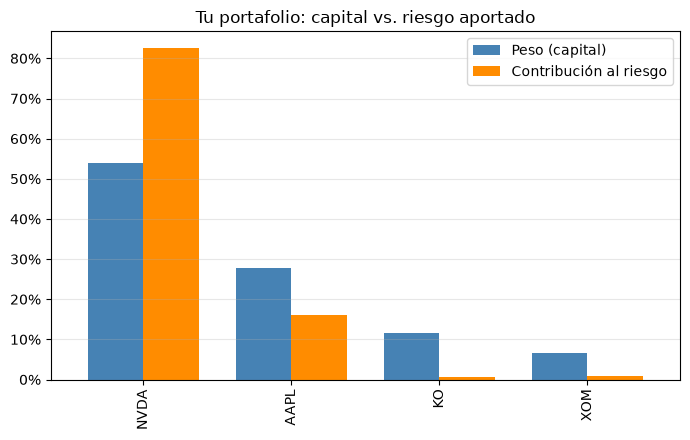

**Tu portafolio frente al sugerido, igual peso y el benchmark:**

,Volatilidad esperada,Sharpe esperado,Activos efectivos,Sharpe histórico,Máx. drawdown histórico,Sharpe fuera de muestra
Mi portafolio,31.8%,1.12,2.59,1.15,-42.7%,0.85
HRP (sugerido),14.3%,1.17,4.77,1.26,-15.9%,1.76
Igual peso,19.5%,1.06,8.00,1.15,-25.7%,1.18
[SPY],16.7%,-,-,0.70,-24.5%,0.66


> **Tus resultados**
>
> - Valor actual: **$12,516.70** en 4 empresas, equivalente a **2.6** empresas a igual peso.
> - Tu mayor posición es **NVDA** (54% del dinero). Tu mayor fuente de riesgo es **NVDA** (83% del riesgo).
> - Más del 40 % de tu riesgo depende de NVDA: estás **poco diversificado**.
> - Tu volatilidad esperada es 31.8%; con estas mismas empresas se puede bajar hasta 13.8% (estrategia de menor riesgo).
> - Fuera de muestra, tus pesos actuales quedaron **#8 de 8** en Sharpe (0.85 vs. 1.76 de *HRP*).

In [12]:
@tab.seccion
def _():
    A = tab.A
    if A.posiciones is None:
        display(Markdown("*No indicaste tus acciones. Escríbelas en el panel (**Mis acciones**, p. ej. "
                         "`AAPL: 10, KO: 25`) y pulsa **Analizar** para ver esta sección.*"))
        return
    display(ac.estilo_posiciones(A.posiciones))
    ac.graf_contribucion(A.pesos[ac.MI_PORTAFOLIO], A.S, "Tu portafolio: capital vs. riesgo aportado"); plt.show()
    display(Markdown("**Tu portafolio frente al sugerido, igual peso y el benchmark:**"))
    display(ac.estilo_comparar_mi(ac.comparar_mi_portafolio(A)))
    display(Markdown(ac.lectura_mi_portafolio(A)))

### Plan de rebalanceo: qué comprar y qué vender

Para pasar de tu portafolio actual a una estrategia, se calcula cuántas acciones **enteras** necesitarías de cada
empresa y la diferencia con lo que ya tienes. Abajo, el plan hacia la estrategia sugerida sin meter dinero nuevo;
en el explorador puedes elegir otra estrategia y agregar (o retirar) dinero.

Antes de ejecutar un plan así, considera las **comisiones** y los **impuestos** por vender con ganancia: a veces
conviene rebalancear poco a poco, usando el dinero nuevo para comprar lo que falta en lugar de vender.

In [13]:
@tab.seccion
def _():
    A = tab.A
    if A.posiciones is None:
        return
    plan, resumen = ac.plan_rebalanceo(A.cfg.posiciones, A.w, A.precios)
    display(Markdown(f"**Hacia *{A.elegido}* (sugerido), sin dinero nuevo:**"))
    display(ac.estilo_rebalanceo(plan))
    display(ac.estilo_resumen_rebalanceo(resumen))

    def explorar(objetivo, aporte):
        plan, resumen = ac.plan_rebalanceo(A.cfg.posiciones, A.pesos[objetivo], A.precios, aporte)
        display(ac.estilo_rebalanceo(plan))
        display(ac.estilo_resumen_rebalanceo(resumen))

    display(Markdown("**Explora otros objetivos o agrega dinero** (negativo = retirar):"))
    display(ac.Tablero.interactivo(
        explorar,
        objetivo=widgets.Dropdown(options=[e for e in A.pesos if e != ac.MI_PORTAFOLIO], value=A.elegido,
                                  description="Objetivo"),
        aporte=widgets.FloatText(value=0, step=500, description="Aporte ($)"),
    ))

**Hacia *HRP* (sugerido), sin dinero nuevo:**

,Tienes,Objetivo,Precio,Operación,Monto,Peso actual,Peso objetivo
Ticker,,,,,,,
NVDA,40,2,$168.89,Vender 38,"-$6,418",54.0%,2.5%
AAPL,10,4,$348.51,Vender 6,"-$2,091",27.8%,11.7%
AMZN,0,2,$270.87,Comprar 2,+$542,0.0%,4.7%
GOOGL,0,3,$287.38,Comprar 3,+$862,0.0%,5.9%
XOM,5,11,$164.47,Comprar 6,+$987,6.6%,14.0%
MSFT,0,2,$533.16,Comprar 2,"+$1,066",0.0%,8.5%
JPM,0,5,$342.07,Comprar 5,"+$1,710",0.0%,15.3%
KO,15,48,$96.91,Comprar 33,"+$3,198",11.6%,37.3%


,
Valor actual de tus acciones,"$12,516.70"
Dinero nuevo (aporte),$0.00
Total a vender,"$8,508.88"
Total a comprar,"$8,365.40"
Efectivo sobrante,$143.48


**Explora otros objetivos o agrega dinero** (negativo = retirar):

## 12. Simulación de escenarios futuros (Monte Carlo)

Todo lo anterior mira al **pasado**. Esta sección responde la pregunta práctica: *si invierto hoy, ¿cuánto podría
tener dentro de unos años?* No hay una respuesta única, así que se simulan **2,000 futuros posibles** y se observa
el rango de resultados.

**Cómo se generan los escenarios (*block bootstrap*):** cada futuro se arma pegando bloques de ~1 mes de días
**reales** del historial del portafolio, elegidos al azar. A diferencia de suponer una campana normal, así se
conservan las caídas bruscas, las rachas de alta volatilidad y que las acciones se desplomen juntas en las crisis.

**El supuesto de rendimiento importa mucho:**

| Supuesto | Qué hace | Cuándo usarlo |
|---|---|---|
| **Conservador** (por defecto) | Mantiene el riesgo histórico, pero centra el rendimiento en lo que predice CAPM: $R_f + \beta \times$ prima de mercado (5 %) | Para planear |
| **Histórico** | Repite el rendimiento promedio del periodo analizado | Para ver qué pasaría si el futuro fuera igual de bueno (o malo) que el pasado |

Si el periodo analizado fue excepcional (por ejemplo, un auge tecnológico), el supuesto histórico produce
proyecciones **demasiado optimistas**; por eso no es el predeterminado.

**Cómo leer la gráfica:** la línea oscura es el escenario mediano (la mitad termina por encima y la mitad por debajo).
La banda oscura contiene el 50 % central de los escenarios y la clara el 90 %. La línea roja es tu capital inicial:
todo lo que queda por debajo son escenarios con pérdida. A la derecha, cuántos escenarios terminan en cada valor.

**HRP** · $10,000 · 5 años · 2,000 escenarios · supuesto conservador

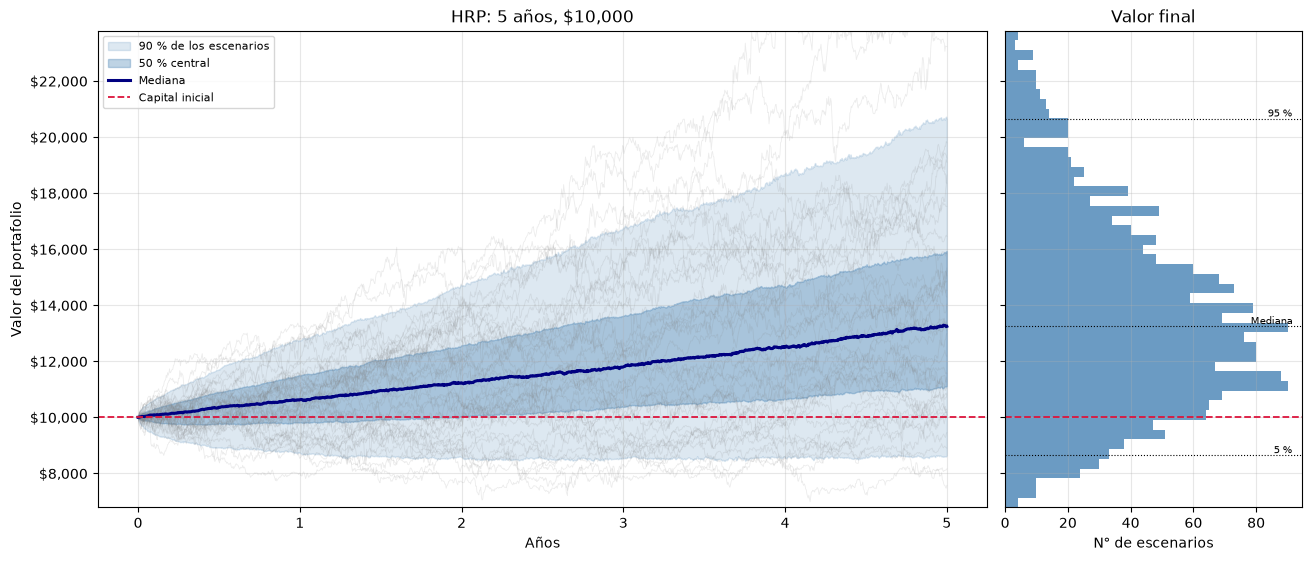

,Valor final,Ganancia / pérdida,Rend. del periodo,Rend. anual
Pesimista (5 %),"$8,638","-$1,362",-13.6%,-2.9%
Desfavorable (25 %),"$11,111","+$1,111",+11.1%,+2.1%
Mediana (50 %),"$13,244","+$3,244",+32.4%,+5.8%
Favorable (75 %),"$15,928","+$5,928",+59.3%,+9.8%
Optimista (95 %),"$20,650","+$10,650",+106.5%,+15.6%


,
Probabilidad de perder dinero,13.9%
Probabilidad de ganarle a la tasa libre de riesgo,66.8%
Valor final promedio,"$13,769"
Peor caída en el camino (mediana),-19.9%
Probabilidad de una caída de 30 % o más,11.8%


> **Tus resultados**
>
> - Supuesto: rendimiento esperado de **6.8% anual** (CAPM), con la volatilidad y las caídas reales del historial.
> - Con **$10,000** en *HRP* durante **5 años**, el escenario típico (mediana) termina en **$13,244** (+5.8% anual).
> - En el 5 % de escenarios más malos terminarías con **$8,638** o menos (-$1,362); en el 5 % más buenos, con $20,650 o más.
> - Probabilidad de terminar perdiendo dinero: **14%** (baja).
> - En la mitad de los escenarios, en algún momento el portafolio cae **20% o más** desde un máximo, aunque termine ganando: hay que estar preparado para aguantarlo sin vender.

**Todas las estrategias con los mismos 2,000 escenarios** (ordenadas por el escenario pesimista):

,Rend. supuesto,Pesimista (5 %),Mediana (50 %),Optimista (95 %),Prob. de perder,Peor caída (mediana)
Mínima volatilidad,7.1%,"$8,643","$13,339","$20,965",14.4%,-20.8%
HRP,6.8%,"$8,638","$13,244","$20,650",13.9%,-19.9%
Paridad de riesgo,7.5%,"$8,510","$13,720","$22,086",14.3%,-22.3%
Mínimo CVaR,6.2%,"$8,451","$12,730","$19,912",16.5%,-19.8%
Inversa volatilidad,8.0%,"$8,072","$13,839","$23,637",16.0%,-24.4%
Igual peso,8.7%,"$7,490","$14,156","$26,452",18.6%,-28.5%
Máximo Sharpe,8.3%,"$7,470","$14,124","$27,418",19.4%,-29.8%
Mi portafolio,10.8%,"$4,764","$14,765","$44,908",28.6%,-46.8%


In [14]:
@tab.seccion
def _():
    A = tab.A
    capital, años = (A.cfg.capital or 10_000), A.cfg.horizonte
    valores, ra = ac.montecarlo(A, A.w, capital, años)
    tabla, stats = ac.resumen_montecarlo(valores, capital, años, A.rf)
    display(Markdown(f"**{A.elegido}** · ${capital:,.0f} · {ac.texto_horizonte(años)} · {len(valores):,} escenarios · supuesto conservador"))
    ac.graf_montecarlo(valores, capital, f"{A.elegido}: {ac.texto_horizonte(años)}, ${capital:,.0f}"); plt.show()
    display(ac.estilo_montecarlo(tabla))
    display(ac.estilo_riesgo_montecarlo(stats))
    display(Markdown(ac.lectura_montecarlo(A.elegido, tabla, stats, capital, años, ra)))
    display(Markdown("**Todas las estrategias con los mismos 2,000 escenarios** (ordenadas por el escenario pesimista):"))
    display(ac.estilo_comparacion(ac.comparar_montecarlo(A, capital, años)))

### Explora otros escenarios

Cambia la estrategia, el horizonte, el capital o el supuesto. Observa en particular:

- Con horizontes más largos, ¿baja la probabilidad de perder dinero? Compara **1 mes** con **10 años**.
- En horizontes cortos (meses) el resultado depende casi solo de la volatilidad: el rendimiento esperado apenas
  se nota. Por eso, para menos de un año se muestra el rendimiento del periodo y no el anualizado.
- ¿Cuánto cambia el resultado entre el supuesto **conservador** y el **histórico**? Esa diferencia es lo que
  arriesgas si das por hecho que el pasado se repetirá.
- Las estrategias más agresivas tienen mejor escenario optimista, pero ¿también peor escenario pesimista?

In [15]:
@tab.seccion
def _():
    A = tab.A

    def explorar(estrategia, años, capital, supuesto):
        if capital <= 0:
            print("El capital debe ser mayor que 0."); return
        valores, ra = ac.montecarlo(A, A.pesos[estrategia], capital, años, supuesto)
        tabla, stats = ac.resumen_montecarlo(valores, capital, años, A.rf)
        ac.graf_montecarlo(valores, capital, f"{estrategia}: {ac.texto_horizonte(años)}, ${capital:,.0f} ({supuesto})"); plt.show()
        display(ac.estilo_montecarlo(tabla))
        display(Markdown(ac.lectura_montecarlo(estrategia, tabla, stats, capital, años, ra)))

    display(ac.Tablero.interactivo(
        explorar,
        estrategia=widgets.Dropdown(options=list(A.pesos), value=A.elegido, description="Estrategia"),
        años=widgets.SelectionSlider(options=ac.HORIZONTES, value=A.cfg.horizonte if A.cfg.horizonte in dict(ac.HORIZONTES).values() else 5,
                                     description="Horizonte",
                                     continuous_update=False),
        capital=widgets.FloatText(value=A.cfg.capital or 10_000, description="Capital ($)"),
        supuesto=widgets.ToggleButtons(options=["conservador", "historico"], value="conservador",
                                       description="Supuesto"),
    ))

## 13. Laboratorio interactivo

Mueve los controles y observa cómo cambia el portafolio **sin volver a descargar datos**.
Preguntas para explorar:

- ¿Qué pasa con "Máximo Sharpe" si subes el peso máximo a 100 % y gamma a 0? (pista: se concentra)
- ¿Cambian mucho los pesos al pasar μ de `historico` a `capm`? Eso muestra cuán frágil es estimar rendimientos.
- ¿La paridad de riesgo cambia con μ? ¿Por qué no?

> Los controles requieren un kernel activo (Jupyter, VS Code o la app). En GitHub o nbviewer no responden.

In [16]:
@tab.seccion
def _():
    A = tab.A
    estrategias = [e for e in A.pesos if e != ac.MI_PORTAFOLIO]

    def laboratorio(estrategia, max_peso, gamma, mu_metodo, cov_metodo):
        c = replace(A.cfg, max_peso=max_peso, gamma=gamma, mu=mu_metodo, cov=cov_metodo)
        p = ac.construir_portafolios(A.precios, A.bench, c, A.rf)
        if estrategia not in p:
            print(f"'{estrategia}' no se pudo calcular con estos parámetros."); return
        m, s = ac.estimar_mu_S(A.precios, A.bench, c, A.rf)
        display(ac.estilo(ac.desempeño_ex_ante({estrategia: p[estrategia]}, m, s, A.rf), colorear=()))
        ac.graf_contribucion(p[estrategia], s, f"{estrategia}: capital vs. riesgo"); plt.show()
        ac.graf_frontera(m, s, p, A.rf, destacar=estrategia, n_aleatorios=2000); plt.show()

    display(ac.Tablero.interactivo(
        laboratorio,
        estrategia=widgets.Dropdown(options=estrategias, description="Estrategia",
                                    value="Máximo Sharpe" if "Máximo Sharpe" in estrategias else estrategias[0]),
        max_peso=widgets.FloatSlider(value=A.cfg.max_peso, min=0.10, max=1.0, step=0.05, description="Peso máx.",
                                     readout_format=".0%", continuous_update=False),
        gamma=widgets.FloatSlider(value=A.cfg.gamma, min=0, max=2, step=0.05, description="Gamma L2",
                                  continuous_update=False),
        mu_metodo=widgets.ToggleButtons(options=["historico", "ema", "capm"], value=A.cfg.mu, description="μ"),
        cov_metodo=widgets.ToggleButtons(options=["ledoit-wolf", "muestral"], value=A.cfg.cov, description="Σ"),
    ))

### Laboratorio 2: validación fuera de muestra

¿Cambia la estrategia ganadora si cambias el tamaño del periodo de prueba o la frecuencia de rebalanceo?
Si el ranking cambia mucho, ninguna estrategia es claramente superior: la diferencia era suerte.

In [17]:
@tab.seccion
def _():
    A = tab.A

    def laboratorio_oos(test, rebalanceo):
        c = replace(A.cfg, test=test, rebalanceo=rebalanceo)
        o = ac.validar_fuera_de_muestra(A.precios, A.bench, c, A.rf)
        if o is None:
            return
        display(Markdown(f"**Entrenamiento:** {o.periodo_train[0]} → {o.periodo_train[1]} · "
                         f"**Prueba:** {o.periodo_test[0]} → {o.periodo_test[1]}"))
        display(ac.estilo(o.metricas[["Rend. anual (CAGR)", "Volatilidad", "Sharpe", "Máx. drawdown"]]))
        ac.graf_crecimiento(o.rendimientos, o.benchmark, "Fuera de muestra: crecimiento de 100"); plt.show()
        display(Markdown(ac.lectura_oos(o)))

    display(ac.Tablero.interactivo(
        laboratorio_oos,
        test=widgets.FloatSlider(value=A.cfg.test, min=0.10, max=0.60, step=0.05, description="% prueba",
                                 readout_format=".0%", continuous_update=False),
        rebalanceo=widgets.Dropdown(options=list(ac.REBALANCEOS), value=A.cfg.rebalanceo,
                                    description="Rebalanceo"),
    ))

## 14. Conclusiones y limitaciones

- **El pasado no se repite tal cual.** Todo se estima con historia; un periodo distinto puede dar pesos muy distintos.
- **Estimar rendimientos es lo más difícil.** En la literatura, las estrategias que solo usan riesgo (paridad de riesgo,
  HRP, mínima volatilidad) suelen sostenerse mejor fuera de muestra que "Máximo Sharpe". Revisa en la sección 9 si
  eso se cumplió con tus acciones.
- **La simulación no es una predicción.** Muestra un rango de resultados plausibles si el riesgo futuro se parece
  al pasado; una crisis distinta a las del historial podría quedar fuera de ese rango.
- **Faltan costos reales:** comisiones, impuestos y *spread* al rebalancear no están incluidos.
- **Sesgo de supervivencia:** elegir acciones que hoy conocemos (porque les fue bien) infla los resultados históricos.
- **Diversificación sectorial:** si todas las acciones son del mismo sector, la correlación alta limita cuánto se puede
  reducir el riesgo.

Para un reporte rápido sin notebook:
```bash
python acciones.py AAPL MSFT KO XOM --capital 10000
```